In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from datetime import timedelta
import numpy as np
import math

# Task 1: Predicting the Price of Gas using Regression

### 1. Load Data

In [37]:
df = pd.read_csv('./Nat_Gas.csv')

In [38]:
df.head(5)

,Dates,Prices
0,10/31/20,10.1
1,11/30/20,10.3
2,12/31/20,11.0
3,1/31/21,10.9
4,2/28/21,10.9


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Dates   48 non-null     object 
 1   Prices  48 non-null     float64
dtypes: float64(1), object(1)
memory usage: 900.0+ bytes


### 2. Clean Data 

In [41]:
# Parse the existing format (MM/DD/YY)
df['Dates'] = pd.to_datetime(df['Dates'], format='%m/%d/%y')

In [50]:
# Sort chronologically to be safe
df = df.sort_values('Dates').reset_index(drop=True)

### 3. Vizualize Data to understand the relationship

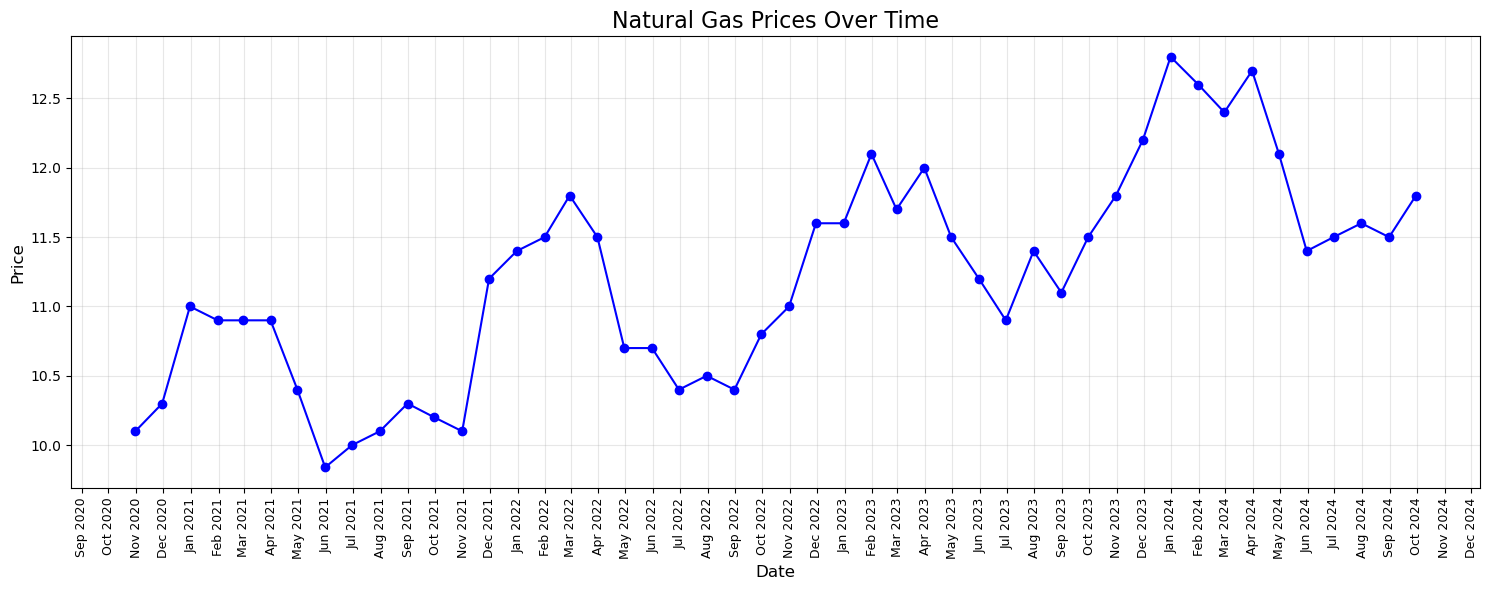

In [51]:
# 3. Create the corrected line plot
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df['Dates'], df['Prices'], marker='o', linestyle='-', color='b')

# 4. Force the x-axis to show EVERY single month
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Rotate the labels so they don't overlap
plt.xticks(rotation=90, fontsize=9)

plt.title('Natural Gas Prices Over Time', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Introduce wave functions to understand fluctuation of prices for the model

a straight line model can only go up or down forever but gas prices they rise, peak in winter, fall, bottom out in summer, then rise again next winter, year after year. The sine and cosine columns give the regression two wave shaped inputs it can scale and combine (c*Sin + d*Cos) to reproduce any repeating up down pattern, with the algorithm figuring out the best fit peak timing

In [53]:
# Day 0 as the  first date of the data
start_date = df['Dates'].min()

# A continuous time variable: days elapsed since the start (it is cumulative)
df['Days'] = (df['Dates'] - start_date).dt.days


the price fluctuates every 12 months or 365 days .A pure linear model (price = a + b*t) can only draw a straight line . it cannot fluctuate  so Sine and cosine waves are used to introduce the cycle, so adding them as extra input columns lets a regression model bend into the repeating shape, that will range from -1 to 1 for 365 days

In [55]:

df['Sin'] = np.sin(2 * np.pi * df['Days'] / 365.25)
df['Cos'] = np.cos(2 * np.pi * df['Days'] / 365.25)

Having both Sin and Cos as separate regression inputs lets the model find its own coefficients (c and d) for each, and the combination c*Sin + d*Cos can reconstruct a sine wave of any phase and amplitude. the regression chooses where the peak falls and how big the swing is, by fitting c and d to actual price data.

The regression becomes

price(t) = a + b*t + c*Sin(t) + d*Cos(t)

In [56]:
# Fit the regression model
X = df[['Days', 'Sin', 'Cos']]
y = df['Prices']
model = LinearRegression()
model.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 5. Predict the Prices using the model

In [77]:
def estimate_price(target_date_str):
    
     # Convert input string to a pandas datetime object
    target_date = pd.to_datetime(target_date_str)
    days_from_start = (target_date - start_date).days
    sin_val = np.sin(2 * np.pi * days_from_start / 365.25)
    cos_val = np.cos(2 * np.pi * days_from_start / 365.25)
    predicted_price = model.predict([[days_from_start, sin_val, cos_val]])
    return predicted_price[0]

#### Testing Price Prediction

In [78]:
## For May 2025( Onto the next year)

estimated_price= estimate_price('2025-05-30')
print(estimated_price)

12.341403067192939


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Task 2: Determining the value  of Gas  Contract

### 2.1. Calculates the total profit (value) of a natural gas storage contract.

In [82]:

def price_storage_contract(
    injection_dates, 
    withdrawal_dates,
    volume_per_injection, 
    volume_per_withdrawal, 
    max_volume,
    storage_cost_per_month, 
    injection_cost_per_mmbtu, 
    withdrawal_cost_per_mmbtu, 
    transport_cost_per_trip
):
  # 1. Using  Task 1 model to predict the prices for the provided dates
    injection_prices = [estimate_price(date) for date in injection_dates]
    withdrawal_prices = [estimate_price(date) for date in withdrawal_dates]
    
    # 2. Validate storage limits
    total_injected = len(injection_dates) * volume_per_injection
    if total_injected > max_volume:
        print(f"WARNING: Total injected volume ({total_injected}) exceeds max capacity ({max_volume})!")
        
    # 3. Revenue  : Selling gas at predicted winter prices
    total_revenue = sum([volume_per_withdrawal * price for price in withdrawal_prices])
    
    # 4. Gas Cost : Buying gas at predicted summer prices
    total_gas_cost = sum([volume_per_injection * price for price in injection_prices])
    
    # 5. Pumping Costs 
    total_inj_cost = total_injected * injection_cost_per_mmbtu
    total_with_cost = (len(withdrawal_dates) * volume_per_withdrawal) * withdrawal_cost_per_mmbtu
    
    # 6. Transport Costs
    total_transport_cost = (len(injection_dates) + len(withdrawal_dates)) * transport_cost_per_trip
    
    # 7. Storage Rent 
    all_dates = pd.to_datetime(injection_dates + withdrawal_dates)
    days_stored = (all_dates.max() - all_dates.min()).days
    months_stored = math.ceil(days_stored / 30.4) 
    total_storage_rent = months_stored * storage_cost_per_month
    
    # 8. Final Contract Value
    contract_value = total_revenue - total_gas_cost - total_inj_cost - total_with_cost - total_transport_cost - total_storage_rent
    
    print(f"Predicted Buy Prices: {[f'${p:.2f}' for p in injection_prices]}")
    print(f"Predicted Sell Prices: {[f'${p:.2f}' for p in withdrawal_prices]}")
    
    
    return contract_value

Testing 

In [84]:
automated_value = price_storage_contract(
    injection_dates=['2024-07-15'],        
    withdrawal_dates=['2025-01-15'],      
    
    volume_per_injection=1000000,
    volume_per_withdrawal=1000000,
    max_volume=5000000,
    
    storage_cost_per_month=100000,
    injection_cost_per_mmbtu=0.005,
    withdrawal_cost_per_mmbtu=0.005,
    transport_cost_per_trip=50000
)

print(f"Total Estimated Contract Value: ${automated_value:,.2f}")


Predicted Buy Prices: ['$11.51']
Predicted Sell Prices: ['$13.10']
Total Estimated Contract Value: $778,533.99


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
